# Materials, layers and envelope roles

Construct physical assemblies explicitly and distinguish the top-floor boundary from the external roof shell.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

`MaterialSpec` stores physical properties, `LayerSpec` gives a material a thickness, and `ConstructionSpec` orders layers **outside to inside**. `EnvelopeSpec` assigns those constructions to wall, occupied top, ground, intermediate slab and other physical boundary roles.

For nominal U-value reporting, layer resistance is thickness divided by conductivity, and `U = 1 / (R_surface + Σ thickness/conductivity)`. EnergyPlus calculates convection dynamically; the nominal surface resistance is not a second material layer. The roof figure helps distinguish the occupied ceiling's `top` role from the attic's external `weather_shell`.

Reference: [Resolved roof shells, openings and attached shading](../../docs/figures/roof-and-facade.svg). This linked documentation illustration is separate from the outputs computed below.

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


### Material properties become an assembly

A material has no thickness. LayerSpec supplies thickness; ConstructionSpec preserves layer order; EnvelopeSpec assigns the assembly to a building element. The section plot below uses the actual layer thicknesses. National archetypes need construction provenance and uncertainty, not just a nominal U-value.

The following original diagram is conceptual API guidance; the later charts and tables report the computed example values.

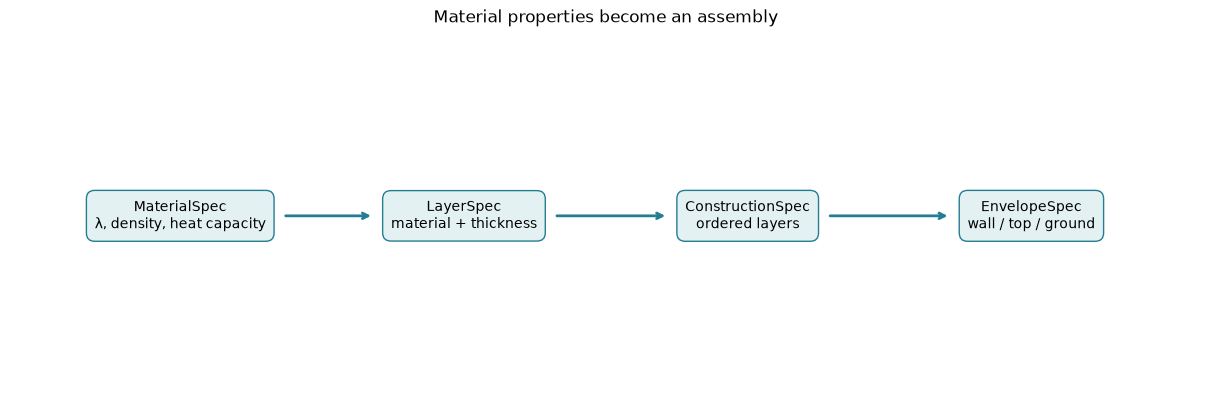

In [2]:
from demo.support.common import flow
flow(['MaterialSpec\nλ, density, heat capacity', 'LayerSpec\nmaterial + thickness', 'ConstructionSpec\nordered layers', 'EnvelopeSpec\nwall / top / ground'], 'Material properties become an assembly', figsize=(12, 4))

## Build and inspect material layers

Conductivity, density and heat capacity describe different physical effects. Layer order is explicit; the calculated nominal U-value includes the construction surface resistance.

### Read the code and output

Read conductivity in W/(m·K), density in kg/m³, specific heat in J/(kg·K) and thickness in metres. A material's conductivity does not tell you its assembly U-value until thickness and other layers are specified. The horizontal section shows order and depth; it is not a geometric wall extrusion in the energy model.

Reference: [How geometry feeds compilation, physical quantities and inspection](../../docs/figures/geometry-pipeline.svg). This linked documentation illustration is separate from the outputs computed below.

,material,thickness_m,R_m2K_W
0,illustrative mineral wool,0.15,3.750000
1,illustrative concrete,0.20,0.117647


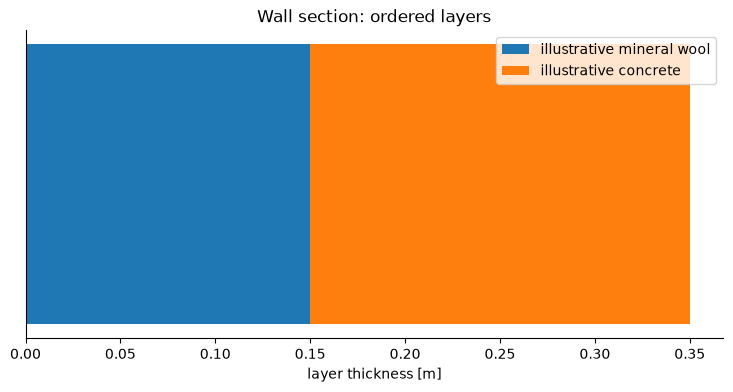

In [3]:
concrete = MaterialSpec(name="illustrative concrete",conductivity_w_mk=1.7,density_kg_m3=2300,specific_heat_j_kgk=880)
wool = MaterialSpec(name="illustrative mineral wool",conductivity_w_mk=.04,density_kg_m3=40,specific_heat_j_kgk=840)
wall = ConstructionSpec(layers=(LayerSpec(material=wool,thickness_m=.15),LayerSpec(material=concrete,thickness_m=.2)))
table([{"material":l.material.name,"thickness_m":l.thickness_m,"R_m2K_W":l.thickness_m/l.material.conductivity_w_mk} for l in wall.layers])
fig,ax = plt.subplots(figsize=(9, 4)); left=0
for layer in wall.layers:
    ax.barh([0],layer.thickness_m,left=left,label=layer.material.name); left+=layer.thickness_m
ax.set(xlabel="layer thickness [m]",title="Wall section: ordered layers",yticks=[]); ax.legend(); plt.show(); plt.close(fig)

## Check resistance and thickness sensitivity

This is a steady-state assembly calculation, not an annual building simulation. Extra insulation reduces nominal U-value but does not specify thermal bridges automatically.

### Read the code and output

Increasing only the insulation layer changes nominal conductance while preserving the concrete layer. The assertion independently checks the series-resistance calculation. Thermal bridge uplift is a separate envelope assumption and is not automatically derived from the junctions in the rendered building.

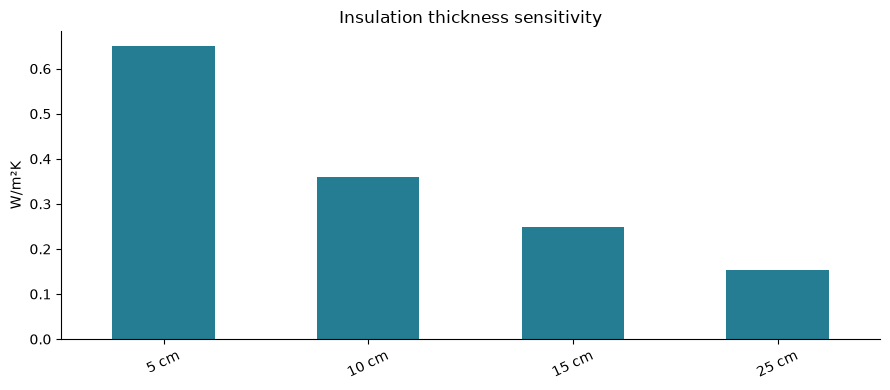

In [4]:
resistance = wall.surface_resistance_m2k_w + sum(l.thickness_m/l.material.conductivity_w_mk for l in wall.layers)
assert np.isclose(wall.u_value_w_m2k,1/resistance)
bars({f"{d*100:.0f} cm":wall.updated(layers=(wall.layers[0].updated(thickness_m=d),wall.layers[1])).u_value_w_m2k for d in [.05,.1,.15,.25]}, "W/m²K", "Insulation thickness sensitivity")

## Assign physical boundary roles

Envelope roles let a cold attic use a top-floor ceiling construction independently from its weather shell. Basement walls and ceilings also have explicit assignments.

### Read the code and output

The same construction can serve several roles in a teaching example, but each role remains explicit so observed buildings can differ. A cold attic's exterior roof shell and occupied ceiling need not have the same insulation. Use the pipeline figure to see how these physical roles feed both compilation and quantity reporting.

In [5]:
slab = ConstructionSpec(layers=(wall.layers[1],))
envelope = EnvelopeSpec(wall=wall,top=wall,ground=wall,intermediate_floor=slab,weather_shell=slab,basement_wall=wall,basement_ceiling=wall)
table({role:value.u_value_w_m2k for role,value in envelope.__dict__.items() if isinstance(value,ConstructionSpec)})

,field,value
0,wall,0.24766899766899764
1,top,0.24766899766899764
2,ground,0.24766899766899764
3,intermediate_floor,3.476482617586912
4,weather_shell,3.476482617586912
5,basement_wall,0.24766899766899764
6,basement_ceiling,0.24766899766899764


,field,value
0,wall,0.24766899766899764
1,top,0.24766899766899764
2,ground,0.24766899766899764
3,intermediate_floor,3.476482617586912
4,weather_shell,3.476482617586912
5,basement_wall,0.24766899766899764
6,basement_ceiling,0.24766899766899764


## Interpretation and next experiment

National archetypes can share explicit assemblies, but measured construction evidence and assumed defaults should remain distinguishable.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.